In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:

!nvidia-smi
!which nvcc
!nvcc --version
!g++ --version
!nproc


Mon Oct 19 16:24:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:

!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
!lscpu


name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.178.04
Tesla T4, 15360 MiB, 580.178.04
Architecture:                x86_64
  CPU op-mode(s):            32-bit, 64-bit
  Address sizes:             46 bits physical, 48 bits virtual
  Byte Order:                Little Endian
CPU(s):                      4
  On-line CPU(s) list:       0-3
Vendor ID:                   GenuineIntel
  Model name:                Intel(R) Xeon(R) CPU @ 2.00GHz
    CPU family:              6
    Model:                   85
    Thread(s) per core:      2
    Core(s) per socket:      2
    Socket(s):               1
    Stepping:                3
    BogoMIPS:                4000.40
    Flags:                   fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pg
                             e mca cmov pat pse36 clflush mmx fxsr sse sse2 ss h
                             t syscall nx pdpe1gb rdtscp lm constant_tsc rep_goo
                             d nopl xtopology nonstop_tsc cpuid tsc_known_fr

In [4]:
%%writefile cpu.cpp
#include <iostream>
#include <vector>
#include <omp.h>
using namespace std;

int main() {
    int sizes[] = {128, 256, 512, 1024, 2048, 3072};

    for (int n : sizes) {
        vector<float> A((size_t)n * n, 1.0f);
        vector<float> B((size_t)n * n, 2.0f);
        vector<float> C((size_t)n * n, 0.0f);

        double start = omp_get_wtime();

        #pragma omp parallel for schedule(static)
        for (int i = 0; i < n; i++) {
            for (int k = 0; k < n; k++) {
                float a = A[(size_t)i * n + k];
                for (int j = 0; j < n; j++) {
                    C[(size_t)i * n + j] +=
                        a * B[(size_t)k * n + j];
                }
            }
        }

        double end = omp_get_wtime();

        cout << n << "," << omp_get_max_threads()
             << "," << (end - start) * 1000.0
             << "," << C[0] << "\n";
    }
}

Writing cpu.cpp


In [5]:
!g++ -O3 -fopenmp cpu.cpp -o cpu
!./cpu

128,4,0.618386,256
256,4,2.6112,512
512,4,19.6889,1024
1024,4,158.335,2048
2048,4,1259.11,4096
3072,4,4891.54,6144


In [10]:
%%writefile gpu.cu

#include <iostream>
#include <vector>
#include <cuda_runtime.h>
using namespace std;

#define TILE 16


#define CHECK(call) do { \
    cudaError_t cuda_status = (call); \
    if (cuda_status != cudaSuccess) { \
        cerr << cudaGetErrorString(cuda_status) << "\n"; \
        return 1; \
    } \
} while (0)


__global__ void matmul(const float *A, const float *B,
                       float *C, int n) {
    __shared__ float As[TILE][TILE];
    __shared__ float Bs[TILE][TILE];

    int row = blockIdx.y * TILE + threadIdx.y;
    int col = blockIdx.x * TILE + threadIdx.x;
    float sum = 0.0f;

    for (int t = 0; t < (n + TILE - 1) / TILE; t++) {
        int ak = t * TILE + threadIdx.x;
        int bk = t * TILE + threadIdx.y;

        As[threadIdx.y][threadIdx.x] =
            (row < n && ak < n) ? A[row * n + ak] : 0.0f;

        Bs[threadIdx.y][threadIdx.x] =
            (bk < n && col < n) ? B[bk * n + col] : 0.0f;

        __syncthreads();

        for (int k = 0; k < TILE; k++)
            sum += As[threadIdx.y][k] * Bs[k][threadIdx.x];

        __syncthreads();
    }

    if (row < n && col < n)
        C[row * n + col] = sum;
}

int main() {
    int sizes[] = {128, 256, 512, 1024, 2048, 3072};

    for (int n : sizes) {
        size_t bytes = (size_t)n * n * sizeof(float);

        vector<float> A((size_t)n * n, 1.0f);
        vector<float> B((size_t)n * n, 2.0f);
        vector<float> C((size_t)n * n);

        float *dA, *dB, *dC;
        CHECK(cudaMalloc(&dA, bytes));
        CHECK(cudaMalloc(&dB, bytes));
        CHECK(cudaMalloc(&dC, bytes));

        cudaEvent_t s, e, hs, he, ds, de;
        CHECK(cudaEventCreate(&s));
        CHECK(cudaEventCreate(&e));
        CHECK(cudaEventCreate(&hs));
        CHECK(cudaEventCreate(&he));
        CHECK(cudaEventCreate(&ds));
        CHECK(cudaEventCreate(&de));

        CHECK(cudaEventRecord(hs));
        CHECK(cudaMemcpy(dA, A.data(), bytes,
                         cudaMemcpyHostToDevice));
        CHECK(cudaMemcpy(dB, B.data(), bytes,
                         cudaMemcpyHostToDevice));
        CHECK(cudaEventRecord(he));
        CHECK(cudaEventSynchronize(he));

        float h2d;
        CHECK(cudaEventElapsedTime(&h2d, hs, he));

        int blocks = (n + TILE - 1) / TILE;
        dim3 threads(TILE, TILE);
        dim3 grid(blocks, blocks);

        CHECK(cudaEventRecord(s));
        matmul<<<grid, threads>>>(dA, dB, dC, n);
        CHECK(cudaGetLastError());
        CHECK(cudaEventRecord(e));
        CHECK(cudaEventSynchronize(e));

        float kernel;
        CHECK(cudaEventElapsedTime(&kernel, s, e));

        CHECK(cudaEventRecord(ds));
        CHECK(cudaMemcpy(C.data(), dC, bytes,
                         cudaMemcpyDeviceToHost));
        CHECK(cudaEventRecord(de));
        CHECK(cudaEventSynchronize(de));

        float d2h;
        CHECK(cudaEventElapsedTime(&d2h, ds, de));

        cout << n << "," << h2d << "," << kernel
             << "," << d2h << ","
             << h2d + kernel + d2h << ","
             << C[0] << "\n";

        cudaEventDestroy(s);
        cudaEventDestroy(e);
        cudaEventDestroy(hs);
        cudaEventDestroy(he);
        cudaEventDestroy(ds);
        cudaEventDestroy(de);
        cudaFree(dA);
        cudaFree(dB);
        cudaFree(dC);
    }
}


Overwriting gpu.cu


In [11]:

!nvcc -O3 gpu.cu -o gpu
!./gpu


nvcc warning : Support for offline compilation for architectures prior to '<compute/sm/lto>_75' will be removed in a future release (Use -Wno-deprecated-gpu-targets to suppress warning).
128,0.102176,0.239776,0.039872,0.381824,256
256,0.190592,0.09184,0.094528,0.37696,512
512,0.702816,0.562912,0.336384,1.60211,1024
1024,1.97251,4.29296,1.05824,7.32371,2048
2048,7.69184,34.3193,4.59184,46.6029,4096
3072,17.94,124.791,9.55184,152.283,6144


In [12]:

!./cpu > cpu_results.csv
!./gpu > gpu_results.csv


In [13]:

import pandas as pd

cpu = pd.read_csv(
    "cpu_results.csv",
    header=None,
    names=["size", "cpu_threads", "cpu_ms", "cpu_check"]
)

gpu = pd.read_csv(
    "gpu_results.csv",
    header=None,
    names=[
        "size", "h2d_ms", "kernel_ms",
        "d2h_ms", "gpu_component_sum_ms", "gpu_check"
    ]
)

df = cpu.merge(gpu, on="size")

# Primary comparison: use this as a preliminary estimate.
# Replace with repeated median timings in the final experiment.
df["gpu_ms"] = df["gpu_component_sum_ms"]
df["speedup"] = df["cpu_ms"] / df["gpu_ms"]
df["throughput_gflops"] = (
    2 * df["size"]**3 / (df["gpu_ms"] * 1e6)
)
df["transfer_fraction_pct"] = (
    (df["h2d_ms"] + df["d2h_ms"]) / df["gpu_ms"] * 100
)

df.to_csv("s01_results.csv", index=False)
display(df.round(3))


,size,cpu_threads,cpu_ms,cpu_check,h2d_ms,kernel_ms,d2h_ms,gpu_component_sum_ms,gpu_check,gpu_ms,speedup,throughput_gflops,transfer_fraction_pct
0,128,4,0.533,256,0.087,0.279,0.042,0.408,256,0.408,1.306,10.276,31.611
1,256,4,2.457,512,0.180,0.093,0.094,0.368,512,0.368,6.680,91.244,74.643
2,512,4,20.024,1024,0.746,0.561,0.365,1.671,1024,1.671,11.981,160.609,66.452
3,1024,4,158.058,2048,2.113,4.293,1.023,7.429,2048,7.429,21.277,289.084,42.212
4,2048,4,1262.860,4096,7.663,34.318,3.983,45.964,4096,45.964,27.475,373.771,25.337
5,3072,4,4645.470,6144,17.722,124.809,9.321,151.852,6144,151.852,30.592,381.833,17.809


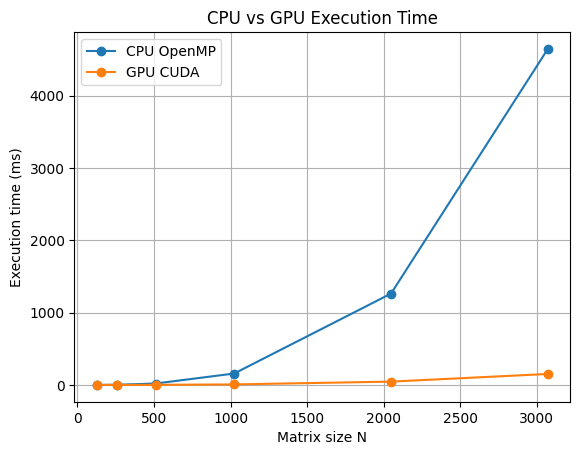

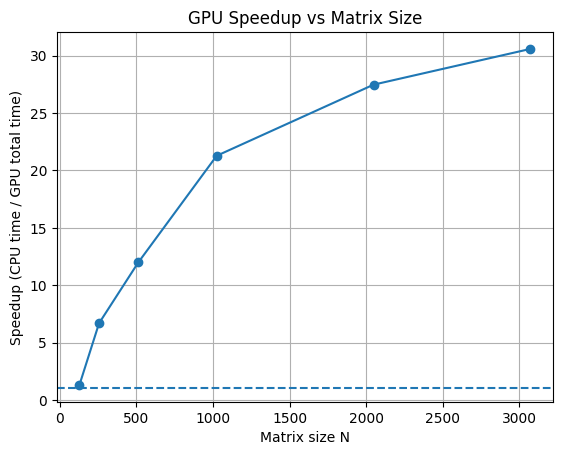

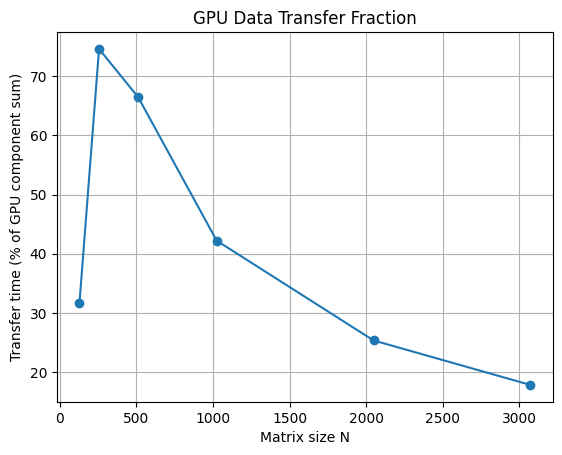

In [14]:

import matplotlib.pyplot as plt

# 1. Execution time vs matrix size
plt.figure()
plt.plot(df["size"], df["cpu_ms"], marker="o", label="CPU OpenMP")
plt.plot(df["size"], df["gpu_ms"], marker="o", label="GPU CUDA")
plt.xlabel("Matrix size N")
plt.ylabel("Execution time (ms)")
plt.title("CPU vs GPU Execution Time")
plt.legend()
plt.grid(True)
plt.savefig("time_vs_size.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Speedup vs matrix size
plt.figure()
plt.plot(df["size"], df["speedup"], marker="o")
plt.axhline(1, linestyle="--")
plt.xlabel("Matrix size N")
plt.ylabel("Speedup (CPU time / GPU total time)")
plt.title("GPU Speedup vs Matrix Size")
plt.grid(True)
plt.savefig("speedup_vs_size.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. Transfer fraction vs matrix size
plt.figure()
plt.plot(
    df["size"], df["transfer_fraction_pct"], marker="o"
)
plt.xlabel("Matrix size N")
plt.ylabel("Transfer time (% of GPU component sum)")
plt.title("GPU Data Transfer Fraction")
plt.grid(True)
plt.savefig("transfer_fraction.png", dpi=300, bbox_inches="tight")
plt.show()
